# WP13 — İki gerçek Türkçe prospektüs / TR_SOURCE_v1

İngilizce kaynaklardan bağımsız belge kimlikleri. Yeni API, OCR, eğitim veya model inference yoktur. Özgün Türkçe terimler yalnız gerçek kaynak sayfa/aralıklarından gösterilir. **Güncellik doğrulanmadı; insan QA PENDING**. Kaynak/hash doğrulaması klinik doğruluk değildir.

## 1. Ürün, tuz, belge ve tarih

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

import wp13_tr_sources_v1 as tr
Q=ROOT/'reports/qa/WP13/tr_source_v1';F=ROOT/'reports/figures/WP13/tr_source_v1'
docs=[tr.load(i) for i in range(2)]
display(pd.DataFrame([{k:d['record'][k] for k in ['product','document_type','composition','currentness','document_revision_date','filename_date_hint','English_product_equivalence']} for d in docs]))
display(pd.read_csv(Q/'page_quality.csv'))


,product,document_type,composition,currentness,document_revision_date,filename_date_hint,English_product_equivalence
0,ERİTRO 500 mg film tablet,KT,500 mg eritromisine eşdeğer 750 mg eritromisin stearat / film tablet,UNVERIFIED_CURRENTNESS,NOT_AVAILABLE_EMPTY_FIELD,NOT_AVAILABLE,NOT_ESTABLISHED
1,MONODOKS 100 mg kapsül,KÜB,"100 mg doksisikline eşdeğer 115,414 mg doksisiklin hiklat / kapsül",UNVERIFIED_CURRENTNESS,NOT_AVAILABLE_EMPTY_FIELD,07-11-2018_UNVERIFIED,NOT_ESTABLISHED


,filename,physical_page,text_sha256,image_count,status,characters,replacement_characters
0,eritro-500-mg-film-tablet-8ccc-kt.pdf,1,39b309489e4443f613b3fad488788be35312ba40b87fa2933426a0284cca76f6,0,TEXT_AVAILABLE,1627,0
1,eritro-500-mg-film-tablet-8ccc-kt.pdf,2,cd620b58ac822183c1311b83d989c233d18c50ede4cf9075fd0796c4c5b726f5,0,TEXT_AVAILABLE,1685,0
2,eritro-500-mg-film-tablet-8ccc-kt.pdf,3,e3c2413a92135c474da26854367e5fdb81a4d117431126e91395dd6a6aa6c070,0,TEXT_AVAILABLE,1729,0
3,eritro-500-mg-film-tablet-8ccc-kt.pdf,4,f0b1544fb98e130048435e316e84d8f6d789f7eea11416333c1367a44781d08c,0,TEXT_AVAILABLE,2316,0
4,eritro-500-mg-film-tablet-8ccc-kt.pdf,5,9ea9e79e6d58cf579c767159c244c523967ba65486db70b4d991f8237921fef2,0,TEXT_AVAILABLE,1721,0
5,eritro-500-mg-film-tablet-8ccc-kt.pdf,6,9063c3f9b770a4321b62501081e65c9ee8e9a05d1edf1da438645a9f8392ff33,0,TEXT_AVAILABLE,1618,0
6,eritro-500-mg-film-tablet-8ccc-kt.pdf,7,f64a1113a858b51eed400916e6880b0863fe15dc9714522c287bf64d9b6d97d0,0,TEXT_AVAILABLE,1637,0
7,eritro-500-mg-film-tablet-8ccc-kt.pdf,8,3ab964c92be08431cdb6d4adfe0be14de1ebf2017d750834b584c6756186499e,0,TEXT_AVAILABLE,1529,0
8,monodoks-100-mg-kapsul-kub-07-11-2018.pdf,1,2494984d643473624a4d4964d9b85f39a07de3aea98d50fca850d8b7896fe595,0,TEXT_AVAILABLE,1868,0
9,monodoks-100-mg-kapsul-kub-07-11-2018.pdf,2,e83a3403fd01edee149b206f9b612305a3d3f588af48e1ee88eaaa81db046872,0,TEXT_AVAILABLE,2365,0


**Yorum:** ERİTRO8, MONODOKS13 fiziksel sayfadır;21 sayfa metin katmanından çıkarıldı, boş/görsel sayfa atlanmadı. Tuz ve dozlar ürün sayfa1 kanıtıyla saklanır. KT onay/KÜB yenilenme alanı boş/yer tutucudur;2018 dosya adı güncellik onayı değildir. İngilizce ürünlerle eşdeğerlik varsayılmaz.

## 2. Gerçek aday sayıları ve sıklık

,product,records,unique_source_terms,unique_names,extra_term_records,clinical_validated_count,scopes.product_specific,frequency.RARE_SOURCE_WORDING,frequency.UNKNOWN,scopes.class_level,scopes.unresolved,repeats.glossit
0,ERİTRO 500 mg film tablet,25,25,25,0,NOT_ESTABLISHED,25,6,19,0.0,0.0,0.0
1,MONODOKS 100 mg kapsül,48,47,47,1,NOT_ESTABLISHED,37,8,40,6.0,5.0,2.0


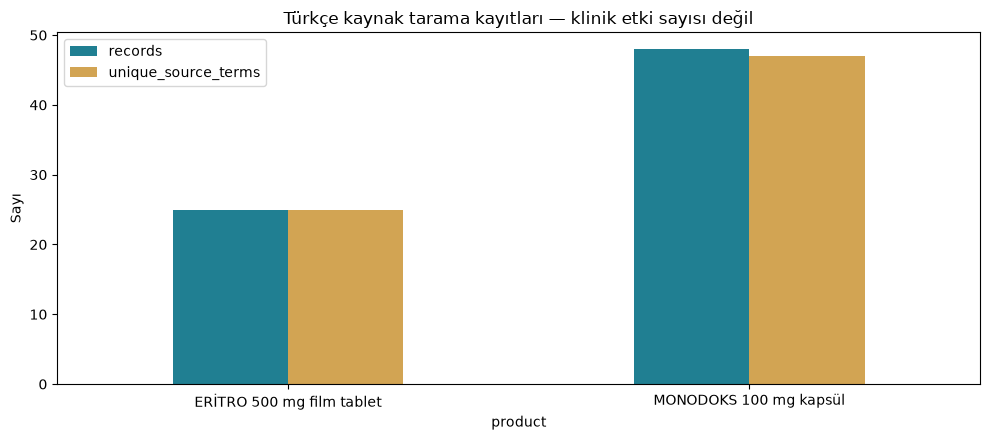

,ürün,aday,sayfa,sıklık,kapsam,inceleme
0,ERİTRO 500 mg film tablet,Nefes darlığı,6,RARE_SOURCE_WORDING,product_specific,PENDING
1,ERİTRO 500 mg film tablet,Baygınlık,6,RARE_SOURCE_WORDING,product_specific,PENDING
2,ERİTRO 500 mg film tablet,"Yüz, dudaklar ya da boğazda şişme",6,RARE_SOURCE_WORDING,product_specific,PENDING
3,ERİTRO 500 mg film tablet,Deri döküntüleri,6,RARE_SOURCE_WORDING,product_specific,PENDING
4,ERİTRO 500 mg film tablet,Ülser ve yara gibi büyük akışkan kabarcıkları kapsayan şiddetli deri reaksiyonları,6,RARE_SOURCE_WORDING,product_specific,PENDING
...,...,...,...,...,...,...
68,MONODOKS 100 mg kapsül,Artralji,10,UNKNOWN,product_specific,PENDING
69,MONODOKS 100 mg kapsül,miyalji,10,UNKNOWN,product_specific,PENDING
70,MONODOKS 100 mg kapsül,BUN artışı,10,UNKNOWN,product_specific,PENDING
71,MONODOKS 100 mg kapsül,diş renginde bozukluk,10,UNKNOWN,class_level,PENDING


In [2]:

counts=pd.read_csv(Q/'count_summary.csv').fillna(0);display(counts)
fig,ax=plt.subplots(figsize=(10,4.5))
counts.set_index('product')[['records','unique_source_terms']].plot.bar(rot=0,ax=ax,color=['#207f92','#d2a453'])
ax.set(title='Türkçe kaynak tarama kayıtları — klinik etki sayısı değil',ylabel='Sayı');plt.tight_layout();plt.savefig(F/'07_actual_TR_counts.png',dpi=160);plt.show()
display(pd.DataFrame([{'ürün':d['record']['product'],'aday':c['name_tr'],'sayfa':c['source']['physical_page'],'sıklık':c['frequency_state'],'kapsam':c['scope'],'inceleme':c['status']} for d in docs for c in d['candidates']]))


**Yorum:** ERİTRO25 madde satırı:6 oldukça seyrek,19 bilinmiyor. MONODOKS48 kayıt/47 terim:glossit iki bölümde. KÜB terimleri ve KT madde satırları farklı birimlerdir; bu sayılar biyolojik kapsam üstünlüğü değildir. MONODOKS37 ürün,6 açık sınıf,5 kısmen belirsiz kapsam; belirsiz5 kayıtta yerel Seyrek başlığının/parantez sonrası kapsamın uzanımı insan incelemesi bekler. Bilinmiyor, seyrek ve sıklık belirtilmemiş birbirine doldurulmaz. Hiçbir aday klinik olarak onaylanmadı.

## 3. BUN / birikim ve ayrı kaynak bağlamları

In [3]:

bun=next(c for c in docs[1]['candidates'] if c['name_tr']=='BUN artışı')
display(pd.DataFrame([bun['source']]+bun['context_quotes'])[['physical_page','statement_kind','scope','quote_exact','quote_id','char_start','char_end']])
display(pd.DataFrame([q for d in docs for q in d['contexts'] if q['statement_kind'] in ['overdose','animal_study']])[['physical_page','statement_kind','scope','quote_exact','quote_id']])
assert all(tr.validate(d) for d in docs)


,physical_page,statement_kind,scope,quote_exact,quote_id,char_start,char_end
0,10,adverse_candidate,product_specific,Bilinmiyor: BUN artışı\n,trquote:63e6f8647b52c81e70ff9aaf53e546c018d735e8a4597571dda1f9c639cf1595,869,892
1,4,warning,class_level,Tetrasiklinlerin antianabolik etkisi BUN artışına neden olabilir.,trquote:f22b901acdc6d7b37abee12214c531288aa600314e7602eb93041163d509d647,1328,1394
2,4,warning,product_specific,"Bugüne kadar yapılmış \nçalışmalar, mutad dozlarda uygulanan MONODOKS 'un böbrek fonksiyon bozuk...",trquote:fa570ca4c8fda7b86e5ffa9719b376cbe2948167e491967488aa96ebc0db15c2,1394,1568


,physical_page,statement_kind,scope,quote_exact,quote_id
0,6,overdose,product_specific,"ERİTRO’nun aşırı dozu geçici işitme kaybı, bulantı, kusma ve ishale neden olabilir. \n \n",trquote:257e5cd7d5f89820fc97862b7d6f065b0ca164e0ac78cc5d46d39072580e3727
1,8,animal_study,class_level,"Hayvanlarda yapılan çalışmaların sonuçları tetrasiklinlerin plasentaya geçtiğini, fetal \ndokula...",trquote:c28216ad97f81979335edf5040530a2e3cbd270fdae2efd4c04ac680d6ff9dac
2,11,animal_study,class_level,5.3 Klinik öncesi güvenlilik verileri,trquote:486fe9ce50b4e59daae5eb53e349b58f91323015287729fe0dc1695a56c45f36
3,12,animal_study,class_level,iyotlu gıdalarla beslenen sıçanlarda yüksek oranda radyoiyot alımı ile büyük bir guatr \nüretmiş...,trquote:2246e449a55c140a2fd5d944497553a533eaaa84ac857cd5a7ff1f2de3bdaedb
4,10,overdose,product_specific,"4.9 Doz aşımı ve tedavisi\nDoksisiklin hiklat aşırı dozuna bağlı klinik belirtiler bulantı, anor...",trquote:6278be4699d602b94d29d94a2370a676b9ce46833608aeef1bf3f0328a498bb2


**Yorum:** 4.8 BUN artışı sıklığı bilinmeyen kayıt olarak kalır.4.2'de tetrasiklin sınıf BUN uyarısı ve MONODOKS birikim yokluğu ayrı kaynak cümleleridir. Birikim yokluğu BUN yokluğu değildir. Aşırı doz ve hayvan bulguları normal kullanım aday tablosuna eklenmedi. Tiroid renk değişimi ile fonksiyon bozukluğunun bilinmediği cümle aynı kanıtta korunur.

## 4. Gerçek localhost ekranları

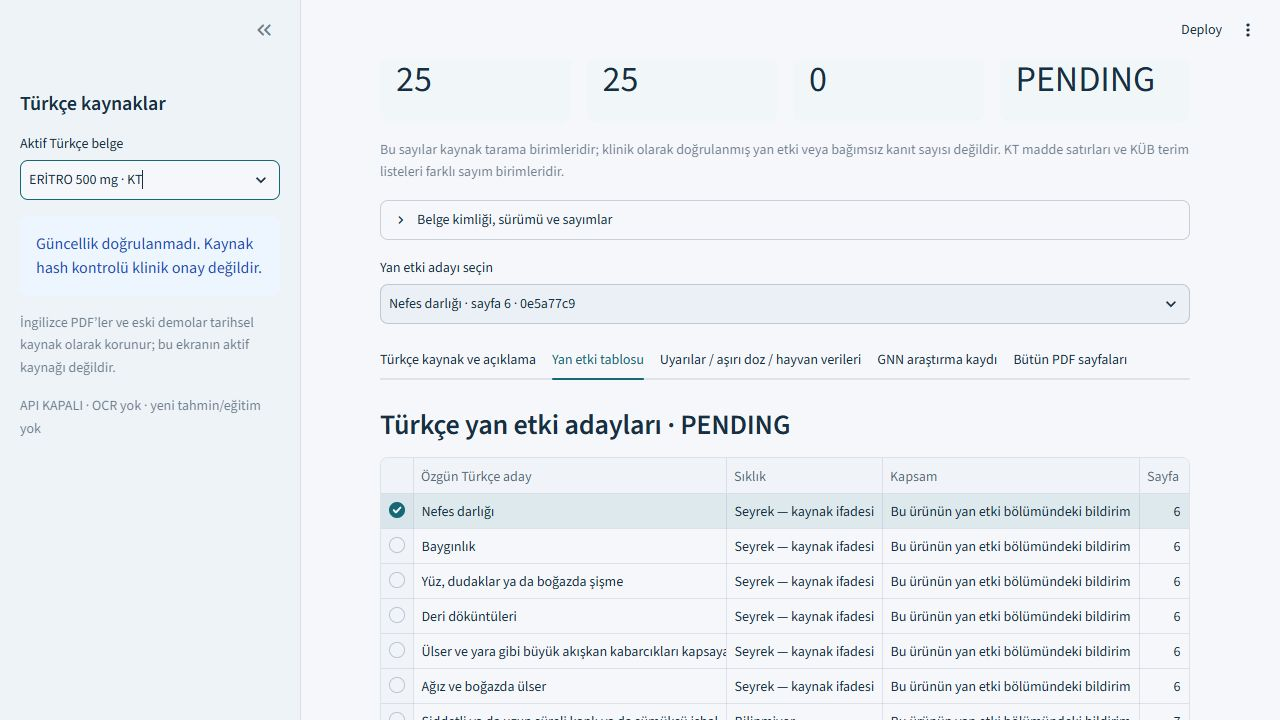

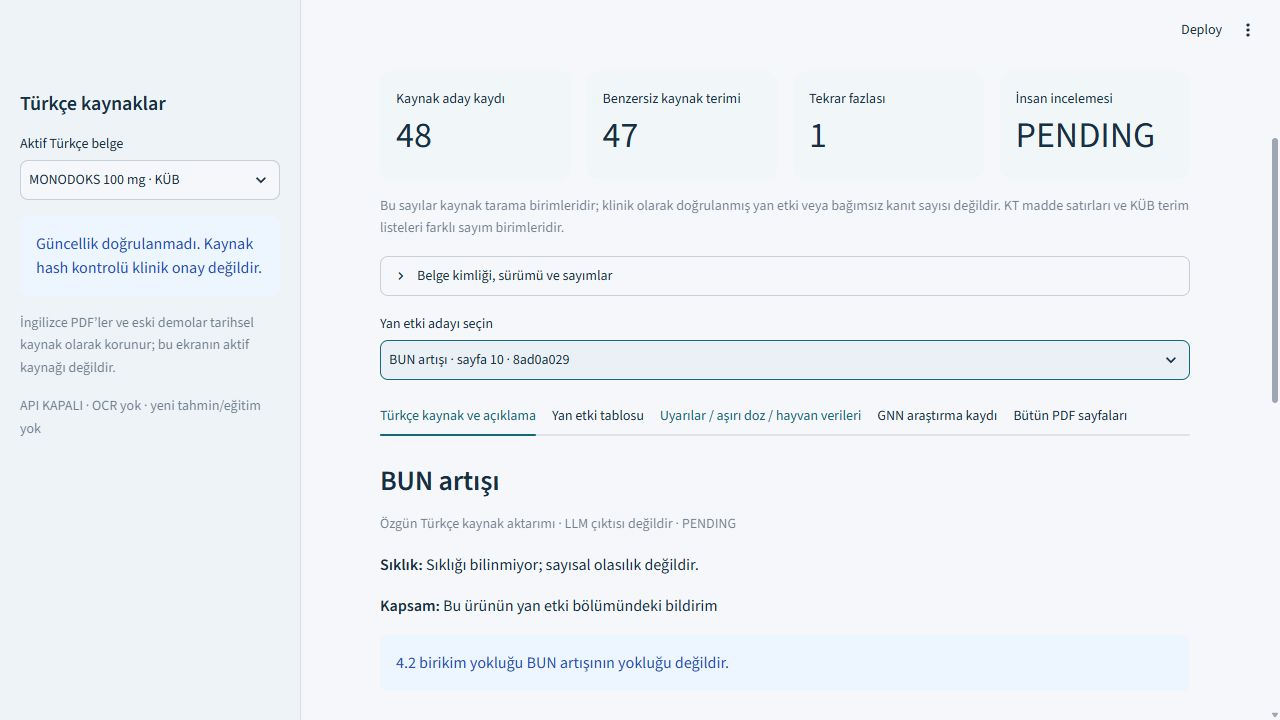

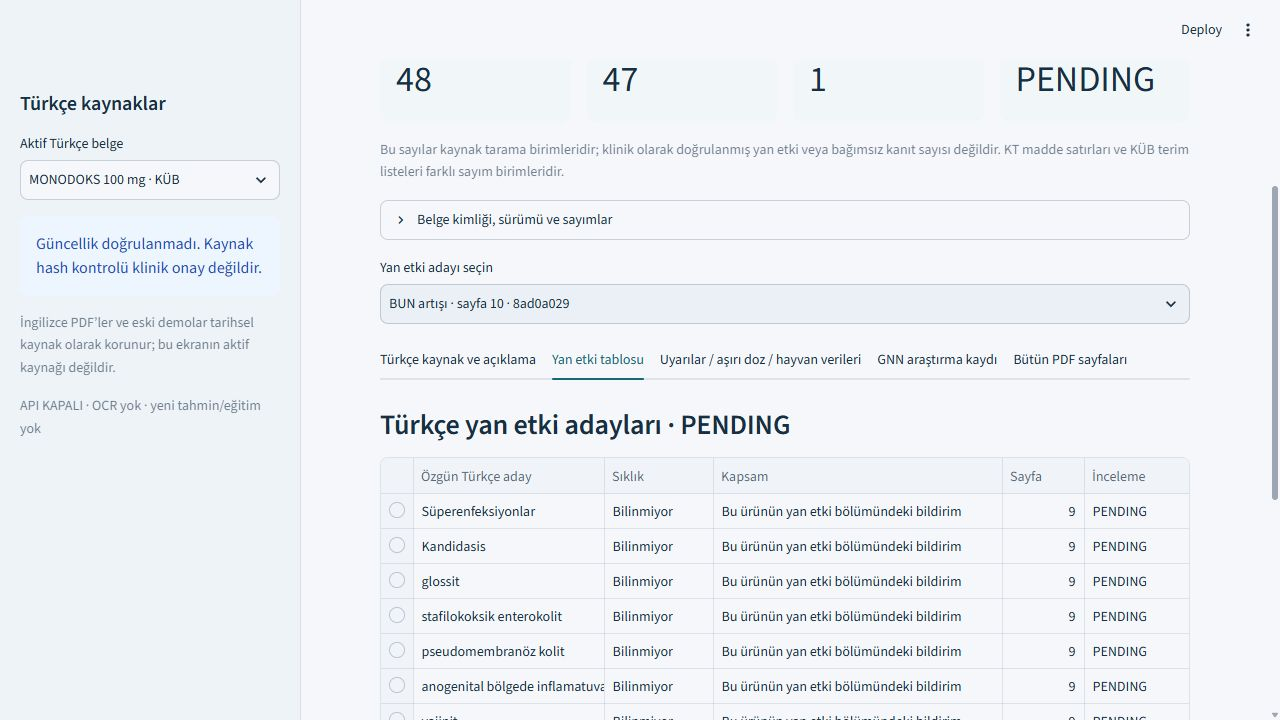

In [4]:

from IPython.display import Image
for f in ['10_final_ERITRO_table.jpg','08_final_MONODOKS_BUN.jpg','09_final_MONODOKS_table.jpg']:
    display(Image(filename=str(F/f),width=1000))


**Yorum:** Görseller gerçek çalışan127.0.0.1:8506 arayüzünden alındı. Yeni Türkçe kaynaklara atıf yapan kayıtlı LLM yanıtı yok:NOT_AVAILABLE. Geçmiş İngilizce açıklamalar Türkçe ürünlerin açıklaması olarak taşınmadı. GNN yalnız ayrı ana etkin madde OOF panelidir; ürün tahmini veya klinik risk değildir. Kaynak PENDING kararları kullanıcı adına değiştirilmedi.